# 06 — Ajuste de la línea base C1 (§5.3)

**Autor:** Jason Sepúlveda S.
**Proyecto:** Evaluación experimental de la extracción automática y la representación
persistente de decisiones organizacionales frente a Recuperación Aumentada (RAG)
**Depende de:** [`05-jss-seleccion-juez.ipynb`](05-jss-seleccion-juez.ipynb) (preguntas
respondibles de ES2015 con su evidencia de referencia) ·
[ADR 0005](../docs/decisions/0005-adr-development-evaluation-split.md) ·
[ADR 0006](../docs/decisions/0006-adr-c1-rag-separado-con-respuesta-de-openkos.md) ·
[ADR 0007](../docs/decisions/0007-adr-ajuste-c1-y-presupuesto-de-contexto.md)

---

> **Estado: decisión tomada.** C1 usa fragmentos de hasta **1.600 caracteres**, **sin
> solapamiento** y recupera **K = 8**. La regla se fijó y se versionó (commit `cfce5af`)
> antes de correr el ajuste; el resultado quedó en `reports/c1-tuning/resultados.json` y los
> parámetros en `[retrieval.c1]` de `config/experiments.toml`.

## Qué hace este notebook

1. Explica por qué C1 debe ajustarse y qué se mide (§1–§3).
2. Muestra la regla prerregistrada, leída de la configuración y no reescrita (§4).
3. Presenta la tabla completa de resultados y la curva de recall frente a K (§5–§6).
4. Registra la decisión y explica por qué las condiciones comparten el presupuesto de texto
   y no el número de bloques (§7–§8).
5. Declara las limitaciones de la medición, en particular que el recall es un piso (§9), y el
   paso siguiente (§10).

## Qué NO hace este notebook

- **No calcula.** Toda cifra viene de una función con prueba de `src/afg/`
  ([`CONTRIBUTING.md` §7.1](../CONTRIBUTING.md)); el notebook importa, llama y explica.
- **No vuelve a correr el ajuste.** Lee el resultado almacenado; repetirlo se hace con
  `uv run afg c1 tune`.
- **No usa ningún modelo generativo ni toca series de evaluación.** Mide solo recuperación,
  sobre una serie de desarrollo.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from afg.conditions.c1_tuning import (
    RESULTS_PATH,
    load_pinned_c1_params,
    load_tuning_config,
    load_tuning_questions,
    load_tuning_results,
    questions_with_any_hit,
    select_winner,
    series_meetings,
)
from afg.evaluation.judge_calibration_generation import CALIBRATION_PATH
from afg.evaluation.judge_calibration_set import development_series
from afg.shared.config import load_experiments_config
from afg.shared.paths import PROJECT_ROOT

pd.set_option("display.width", 140)

# Guarda: el notebook lee el resultado almacenado y la configuracion versionada.
if not RESULTS_PATH.exists():
    raise SystemExit(
        f"No se encontro {RESULTS_PATH}.\n"
        "Genera el resultado con `uv run afg c1 tune` (requiere Ollama con bge-m3)."
    )

CONFIG = load_experiments_config()
TUNING = load_tuning_config()
STORED = load_tuning_results(RESULTS_PATH)
PINNED = load_pinned_c1_params()
print(f"Resultados en {RESULTS_PATH.relative_to(PROJECT_ROOT)}")

Resultados en reports/c1-tuning/resultados.json


---

# 1. Por qué hay que ajustar C1

§5.3 exige que C1 sea una línea base **honesta**: si el tamaño de fragmento y el número de
fragmentos recuperados se eligieran sin evidencia, una ventaja de C2 sobre C1 podría deberse a
una línea base mal configurada y no a la representación persistente. Un C1 sin ajustar
invalida el experimento.

Hay dos parámetros de segmentación y uno de recuperación:

- **`max_chars`**: tamaño máximo de un fragmento, en caracteres.
- **`overlap_turns`**: turnos de habla que comparten dos fragmentos consecutivos.
- **K**: cuántos fragmentos llegan al *prompt* de respuesta.

El K de OpenKOS (`openkos query --limit`, por defecto 5) no tiene justificación documentada:
apareció como valor inicial en el commit `27a71a7d` de OpenKOS. Nadie lo midió sobre
transcripciones de reuniones, de modo que heredarlo para C1 sería arbitrario. Lo que OpenKOS
sí midió es cuánto texto cabe en su *prompt*: 5 cuerpos suman 13.516 caracteres (unos 3.263
*tokens* de los 4.096 reservados). Ese total es el tope que se usa abajo.

---

# 2. Datos y fuga de información

El ajuste usa **ES2015**, una de las tres series de desarrollo
([ADR 0005](../docs/decisions/0005-adr-development-evaluation-split.md)): nada que se ajuste
aquí puede tocar las series cuyos resultados se reportan. La configuración declara las series
y el cargador falla si alguna queda fuera del desarrollo.

Siguiendo D15, el índice contiene **la serie completa** (las cuatro reuniones ES2015a–d), no
reunión por reunión, porque así se responderá cada pregunta en el experimento.

In [2]:
questions = load_tuning_questions(CALIBRATION_PATH, TUNING.series)
by_stratum = pd.Series([q.stratum.value for q in questions]).value_counts().sort_index()
print("Series de desarrollo:", sorted(development_series()))
print("Serie del ajuste    :", list(TUNING.series))
print("Reuniones indexadas :", series_meetings(TUNING.series[0]))
print(f"Preguntas respondibles: {len(questions)}")
by_stratum.rename("preguntas").to_frame()

Series de desarrollo: ['ES2015', 'IS1004', 'TS3009']
Serie del ajuste    : ['ES2015']
Reuniones indexadas : ['ES2015a', 'ES2015b', 'ES2015c', 'ES2015d']
Preguntas respondibles: 17


,preguntas
E1_point_fact,14
E2_current_state,2
E3_evolution,1


---

# 3. La métrica y por qué es solo de recuperación

Para cada pregunta, la referencia incluye los **actos de diálogo** de AMI que sustentan la
respuesta (los enlaces `summlink` del resumen abstractivo). Cada fragmento conoce los actos de
los turnos que cubre. El **recall de evidencia** de una pregunta es la fracción de actos de
referencia contenidos en la unión de los K fragmentos recuperados; la cifra de una
configuración es su promedio sobre las preguntas.

Se mide solo la recuperación, sin modelo generativo, por tres razones:

- **Aísla el parámetro que se ajusta.** Segmentación y K cambian *qué texto llega* al modelo;
  el modelo no interviene en esa decisión.
- **Es barata y determinista.** No depende de la semilla ni de la temperatura del generador,
  y se puede repetir con la rejilla completa.
- **Evita mezclar con el juez.** Una métrica de corrección de respuesta añadiría el error del
  generador y del juez a una decisión que es previa a ambos.

**Comprobación de la medición.** Si se recuperan *todos* los fragmentos, todas las preguntas
alcanzan recall 1,0: los actos de referencia existen siempre en algún fragmento. Por tanto,
todo recall menor que 1 es un fallo de recuperación y no un defecto del índice.

---

# 4. La regla prerregistrada

La rejilla, el presupuesto de caracteres y el margen de empate se fijaron en
`config/experiments.toml` (`[retrieval.tuning]`) y se versionaron en el commit `cfce5af`
**antes de correr nada**. La tabla es esa lectura, no una copia escrita a mano.

In [3]:
pd.DataFrame(
    [
        ("Series de desarrollo indexadas", ", ".join(TUNING.series)),
        ("max_chars (caracteres)", list(TUNING.max_chars)),
        ("overlap_turns", list(TUNING.overlap_turns)),
        ("K", list(TUNING.k)),
        ("char_budget (K x max_chars debe ser <=)", TUNING.char_budget),
        ("tie_margin (empate si la diferencia es <=)", TUNING.tie_margin),
    ],
    columns=["parámetro", "valor"],
)

,parámetro,valor
0,Series de desarrollo indexadas,ES2015
1,max_chars (caracteres),"[800, 1200, 1600, 2400]"
2,overlap_turns,"[0, 1]"
3,K,"[3, 5, 8, 10]"
4,char_budget (K x max_chars debe ser <=),13516
5,tie_margin (empate si la diferencia es <=),0.02


**Regla de decisión.**

1. Es *elegible* una configuración con K × `max_chars` ≤ `char_budget`: nunca se envía más
   texto del que OpenKOS midió como cabida del *prompt*.
2. Entre las elegibles gana la de mayor recall de evidencia medio.
3. Si otras elegibles quedan a no más de `tie_margin` del mejor, se prefiere la de menor K,
   luego la de menor `max_chars`, luego `overlap_turns` = 0. Con 17 preguntas una diferencia
   de 0,02 es ruido; ante un empate práctico se elige lo más barato.

La regla está implementada en `select_winner` (con prueba), y se aplica en la sección 7.

---

# 5. Resultados completos

Una fila por configuración (32 en total). `elegible` indica si cumple el presupuesto de
caracteres; `con acierto` es el número de preguntas en las que algún fragmento recuperado
contiene al menos un acto de referencia; `contexto medio` son los caracteres que llegan al
*prompt* en promedio.

In [4]:
table = pd.DataFrame(
    [
        {
            "max_chars": r.max_chars,
            "overlap": r.overlap_turns,
            "K": r.k,
            "recall medio": round(r.mean_recall, 3),
            "con acierto": f"{questions_with_any_hit(r)}/{STORED.n_questions}",
            "contexto medio": round(r.mean_context_chars),
            "fragmentos": r.n_chunks,
            "elegible": r.eligible,
        }
        for r in STORED.results
    ]
)
table.sort_values(["max_chars", "overlap", "K"]).reset_index(drop=True)

,max_chars,overlap,K,recall medio,con acierto,contexto medio,fragmentos,elegible
0,800,0,3,0.363,7/17,2101,177,True
1,800,0,5,0.392,7/17,3482,177,True
2,800,0,8,0.431,8/17,5557,177,True
3,800,0,10,0.461,9/17,6871,177,True
4,800,1,3,0.304,6/17,2035,194,True
5,800,1,5,0.324,7/17,3485,194,True
6,800,1,8,0.392,8/17,5510,194,True
7,800,1,10,0.495,11/17,6884,194,True
8,1200,0,3,0.304,6/17,3254,112,True
9,1200,0,5,0.520,11/17,5469,112,True


---

# 6. Recall frente a K, por segmentación

Cada línea es una segmentación (`max_chars`, `overlap_turns`). Los marcadores huecos son
configuraciones **no elegibles** (superan el presupuesto de caracteres). La estrella marca el
ganador.

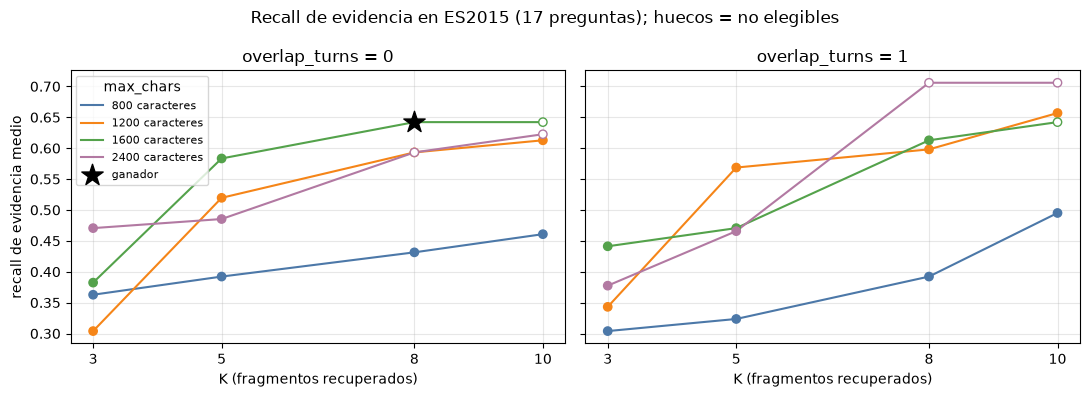

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
colors = {800: "#4c78a8", 1200: "#f58518", 1600: "#54a24b", 2400: "#b279a2"}
for ax, overlap in zip(axes, TUNING.overlap_turns, strict=True):
    for max_chars in TUNING.max_chars:
        rows = sorted(
            (r for r in STORED.results if r.max_chars == max_chars and r.overlap_turns == overlap),
            key=lambda r: r.k,
        )
        ax.plot(
            [r.k for r in rows],
            [r.mean_recall for r in rows],
            color=colors[max_chars],
            label=f"{max_chars} caracteres",
        )
        ax.scatter(
            [r.k for r in rows],
            [r.mean_recall for r in rows],
            facecolors=[colors[max_chars] if r.eligible else "white" for r in rows],
            edgecolors=colors[max_chars],
            zorder=3,
        )
    w = STORED.winner
    if w.overlap_turns == overlap:
        ax.scatter(
            [w.k], [w.mean_recall], marker="*", s=260, color="black", zorder=4, label="ganador"
        )
    ax.set_title(f"overlap_turns = {overlap}")
    ax.set_xlabel("K (fragmentos recuperados)")
    ax.set_xticks(list(TUNING.k))
    ax.grid(alpha=0.3)
axes[0].set_ylabel("recall de evidencia medio")
axes[0].legend(title="max_chars", fontsize=8)
fig.suptitle("Recall de evidencia en ES2015 (17 preguntas); huecos = no elegibles")
fig.tight_layout()
plt.show()

Cuatro lecturas, todas sobre esta serie:

- El recall sube con K y tiende a aplanarse: con 1.600 caracteres y sin solape, de K = 8 a
  K = 10 no cambia (y K = 10 ya no es elegible).
- Entre las configuraciones elegibles con K = 8, 1.600 caracteres (0,642) supera a 1.200
  (0,593): fragmentos más grandes aprovechan mejor cada lugar.
- El tope de texto es lo que limita, no el número de fragmentos: la configuración de mayor
  recall de toda la rejilla (2.400 caracteres, 1 turno de solape, K = 8, recall 0,706) queda
  fuera porque admite hasta 19.200
  caracteres (17.900 de media). La regla prerregistrada la excluye aunque su
  recall sea mayor.
- El solapamiento de un turno no muestra un efecto consistente: a veces mejora y a veces
  empeora el recall, con diferencias del orden del ruido de 17 preguntas.

---

# 7. La decisión

Se aplica la regla de la sección 4 a los resultados almacenados y se contrasta con lo que
quedó fijado en la configuración.

In [6]:
selection = select_winner(STORED.results, TUNING.tie_margin)
w = selection.winner
print(selection.reason)
print()
print(f"Ganador   : max_chars={w.max_chars}, overlap_turns={w.overlap_turns}, K={w.k}")
print(
    f"Fijado en [retrieval.c1]: max_chars={PINNED.max_chars}, "
    f"overlap_turns={PINNED.overlap_turns}, K={PINNED.k}"
)
assert (w.max_chars, w.overlap_turns, w.k) == (PINNED.max_chars, PINNED.overlap_turns, PINNED.k)

best eligible mean recall 0.657; 2 eligible config(s) within 0.02; chose the smallest k, then max_chars, then overlap_turns (recall 0.642).

Ganador   : max_chars=1600, overlap_turns=0, K=8
Fijado en [retrieval.c1]: max_chars=1600, overlap_turns=0, K=8


In [7]:
at_winner = sorted(
    (r for r in STORED.results if (r.max_chars, r.overlap_turns) == (w.max_chars, w.overlap_turns)),
    key=lambda r: r.k,
)
pd.DataFrame(
    {
        "K": [r.k for r in at_winner],
        "recall medio": [round(r.mean_recall, 3) for r in at_winner],
        "preguntas con acierto": [
            f"{questions_with_any_hit(r)}/{STORED.n_questions}" for r in at_winner
        ],
        "contexto medio (caracteres)": [round(r.mean_context_chars) for r in at_winner],
    }
)

,K,recall medio,preguntas con acierto,contexto medio (caracteres)
0,3,0.382,7/17,4456
1,5,0.583,11/17,7443
2,8,0.642,12/17,11996
3,10,0.642,12/17,14919


**Lectura.**

- El mejor elegible (1.200 caracteres, 1 turno de solape, K = 10) tiene recall 0,657. La
  configuración elegida queda a menos de 0,02, así que la regla prefiere la más barata:
  menor K y sin solape.
- Con 1.600 caracteres y sin solape, K = 3 acierta en 7 de 17 preguntas, K = 5 en 11 y K = 8
  en 12; K = 10 no agrega nada. **K = 8 es el primer punto donde el recall deja de crecer.**
- K = 5, el valor que usa OpenKOS, deja a C1 con un recall medio de 0,583 frente a 0,642: una
  línea base con K = 5 estaría deliberadamente debilitada.

---

# 8. Por qué no un K común

Una primera idea era usar el mismo K en las tres condiciones. Se descarta, y las condiciones
comparten en cambio el **presupuesto de texto**:

| | C1 | C2 y C3 |
|---|---|---|
| Recuperación | 8 fragmentos de hasta 1.600 caracteres | `openkos query --limit 5` |
| Contexto medio enviado | unos 12.000 caracteres | unos 13.500 caracteres (lo que OpenKOS midió) |

**Razones.**

- **Lo que el modelo lee es texto.** Un «bloque» significa cosas distintas: en C1, un
  fragmento de transcripción; en C2 y C3, un concepto compilado. Igualar el número de bloques
  no iguala lo que el modelo recibe.
- **K = 8 para C2 enviaría unos 21.600 caracteres**, más de lo que OpenKOS midió como cabida
  de su *prompt*. El contexto se truncaría o quedaría menos espacio para la respuesta, y la
  diferencia entre condiciones dependería del recorte y no de la representación.
- **Se respeta el [ADR 0006](../docs/decisions/0006-adr-c1-rag-separado-con-respuesta-de-openkos.md).**
  `--limit` es una opción pública de OpenKOS; no se modifica su valor por defecto. Si más
  adelante los datos muestran que 5 es insuficiente para C2, se propondrá el cambio en
  OpenKOS con evidencia, no se alterará para la tesis.

La alternativa de forzar K = 5 en C1 se descarta por la razón contraria: pierde recall
medible sin lograr equivalencia real.

In [8]:
shared = CONFIG["retrieval"]
pd.DataFrame(
    [
        ("C1: max_chars", PINNED.max_chars),
        ("C1: overlap_turns", PINNED.overlap_turns),
        ("C1: K", PINNED.k),
        ("C1: contexto medio medido (caracteres)", round(w.mean_context_chars)),
        ("C2/C3: --limit (answer_limit)", shared["answer_limit"]),
        ("Presupuesto de texto de OpenKOS (caracteres, 5 cuerpos)", TUNING.char_budget),
    ],
    columns=["parámetro", "valor"],
)

,parámetro,valor
0,C1: max_chars,1600
1,C1: overlap_turns,0
2,C1: K,8
3,C1: contexto medio medido (caracteres),11996
4,C2/C3: --limit (answer_limit),5
5,"Presupuesto de texto de OpenKOS (caracteres, 5...",13516


---

# 9. Limitación: el recall de evidencia es un piso

El recall cuenta un acierto solo si el fragmento contiene **el acto enlazado** por AMI, y AMI
a menudo enlaza **un solo acto** por respuesta. Un fragmento puede contener la respuesta sin
contener ese acto, y contar igual como fallo.

In [9]:
q016 = next(q for q in questions if q.question_id == "ES2015.q016")
print("Pregunta   :", q016.question)
print("Estrato    :", q016.stratum.value)
for span in q016.evidence:
    print("Evidencia  :", span.meeting_id, list(span.dialogue_act_ids))
print("Recall en el ganador:", w.recalls["ES2015.q016"])

Pregunta   : What energy source was chosen for the remote control?
Estrato    : E1_point_fact
Evidencia  : ES2015c ['ES2015c.A.dialog-act.dharshi.198']
Recall en el ganador: 0.0


El único acto enlazado es el resumen del jefe de proyecto, *«Energy, we've decided on
kinetic, right?»*, mientras que la decisión sobre la fuente de energía se discute en muchos
otros turnos de la reunión. Un fragmento recuperado que contuviera esa discusión sin ese turno
exacto cuenta como fallo.

Consecuencias para la lectura de los resultados:

- Las cifras de recall son un **piso conservador**: el acceso real a la información es mayor
  o igual.
- Es probable que las cinco preguntas sin ningún acierto en el ganador (`q026`, `q016`,
  `q030`, `q010`, `q011`) mezclen fallos reales de recuperación y evidencia enlazada de forma
  estrecha; separar ambos requeriría lectura humana y no se hace aquí.
- Con 17 preguntas de una sola serie, diferencias de 0,01–0,02 entre configuraciones no son
  distinguibles. Por eso la regla prefiere la configuración más barata ante un empate.
- El presupuesto se midió en caracteres, no en *tokens*, y el de C2 se supone a partir de la
  medición de OpenKOS: deberá verificarse cuando se ejecute C2.

Ninguna de estas limitaciones invalida la elección. Sí obligan a no presentar el recall como
una medida de corrección de respuesta.

In [10]:
misses = sorted(q for q, rank in w.first_hit_ranks.items() if rank is None)
print("Preguntas sin ningún acierto en el ganador:", misses)

Preguntas sin ningún acierto en el ganador: ['ES2015.q010', 'ES2015.q011', 'ES2015.q016', 'ES2015.q026', 'ES2015.q030']


---

# 10. Paso siguiente

1. Implementar `src/afg/conditions/c1_document_rag.py` con estos parámetros, leídos con
   `load_pinned_c1_params()` (`[retrieval.c1]`), y los *prompts* de respuesta de OpenKOS
   copiados byte a byte ([ADR 0006](../docs/decisions/0006-adr-c1-rag-separado-con-respuesta-de-openkos.md)).
2. Al ejecutar C2, verificar que el contexto que envía `openkos query --limit 5` cabe en el
   *prompt* tal como OpenKOS lo midió.
3. Reportar la igualdad entre condiciones como igualdad de **presupuesto de texto**
   ([ADR 0007](../docs/decisions/0007-adr-ajuste-c1-y-presupuesto-de-contexto.md)).